# Supplementary Programming Exercises
### MPATE-GE 2598 Fundamentals of Digital Signal Theory Lab

These optional exercises are available for you to practice programming in Python. They do not need to be submitted and will not be graded. 

In [41]:
# Import the libraries you need: numpy, soundfile, and matplotlib
import numpy as np, soundfile as sf, matplotlib.pyplot as plt

### Conditionals and Loops

You are given a list of integers, `a`. Write a block of code that checks whether there are more even or odd numbers in the list and prints `"even"` or `"odd"` accordingly. You should use at least one loop and one conditional statement.

In [42]:
# do not change anything in this cell
a = [176, 403, 661, 416, 454, 999, 352, 527, 921, 784, 800, 866, 545,
     824, 706, 552, 428, 854, 428, 746, 545, 129, 373, 256, 479, 987,
     13, 407,  32]

In [43]:
# YOUR CODE HERE
even = 0
odd = 0
for i in a:
    if (i % 2 == 0):
        even += 1
    else:
        odd += 1
if even > odd:
    print("Even")
else:
    print("Odd")

Even


### Functions

**Wavelength**

Write a function `wavelength` which accepts a frequency as a _required_ input and speed of sound as an _optional_ input, and returns its wavelength. The default speed of sound is 343 m/s.

For reference, the wave equation is $v = f \cdot \lambda$ where $v$ is the speed of sound (m/s), $\lambda$ is wavelength (m), and $f$ is frequency (Hz).

In [44]:
# YOUR CODE HERE
def wavelength(frequency, speed_of_sound = 343):
    wavelength = speed_of_sound / frequency
    return wavelength

Use your function to compute the wavelength of a 8 kHz tone.

In [45]:
# YOUR CODE HERE
wavelength(8000)

0.042875

Now, compute the wavelength of a 440 Hz tone underwater, where the speed of sound is approximately 1481 m/s.

In [46]:
# YOUR CODE HERE
wavelength(440, 1481)

3.3659090909090907

**Decibels (dB)**

Write a function `decibel` which accepts a sound's intensity and a reference intensity to return the level in decibels (dB).

For reference, $dB = 10\log_{10}(\frac{I}{I_0})$, where $I$ is intensity and $I_0$ is reference intensity.

Hint: You can use `np.log10()` to compute $\log_{10}$.

In [47]:
# YOUR CODE HERE
def decibel(intensity, reference_intensity):
    soundLevel = 10 * np.log10(intensity / reference_intensity)
    return soundLevel

Now, compute the decibel level of a sound with an intensity of 10 W and a reference intensity of 0 W.

In [48]:
# YOUR CODE HERE
decibel(10, 0)

ZeroDivisionError: division by zero

Did you get an error? If so, explain why this error was returned (hint: think mathematically).

**Answer:** YOUR ANSWER HERE

Now, rewrite your function below to handle the case where a user inputs a reference intensity of 0 W. Demonstrate that your new function works.

In [ ]:
# YOUR CODE HERE
# Cuz everything divided by 0 is undefined, so we need to think this is a special case, and add a new condition to it. 
def decibel(intensity, reference_intensity):
    if reference_intensity == 0:
        return float('inf')  # Return infinity if reference intensity is 0
    soundLevel = 10 * np.log10(intensity / reference_intensity)
    return soundLevel

decibel(10, 0)

inf

## Audio and Signal Processing Basics

### Load an Audio File

In this directory, you should have a WAV file called `drums.wav` (from [Freesound](https://freesound.org/people/Jedo/sounds/397022/)). In the cell below, load this audio file into the notebook.

In [3]:
# YOUR CODE HERE
import soundfile as sf
from IPython.display import Audio
y, sr = sf.read('drums.wav')


What is the sample rate of the audio?

In [4]:
# YOUR CODE HERE
print(f"Sample Rate: {sr}")


Sample Rate: 48000


Show what kind of data structure the audio is stored as and what data type its values are.

In [5]:
# YOUR CODE HERE
type(y), y.dtype


(numpy.ndarray, dtype('float64'))

Is the audio in stereo or mono? How do you know?

In [6]:
# YOUR CODE HERE
y.shape, y.ndim
# it is stereo, as the shape has two channels

((305291, 2), 2)

**Answer:** YOUR ANSWER HERE

### Audio Playback

Play the audio in the notebook (hint: check your dimensions). Make sure you import any necessary libraries.

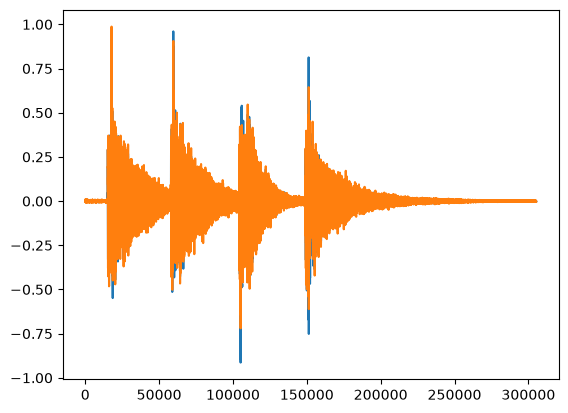

In [10]:
# YOUR CODE HERE
from IPython.display import Audio
Audio(y.T, rate = sr)
import matplotlib.pyplot as plt
plt.plot(y)
plt.show()


Try playing the audio using different sample rates. What do you notice?

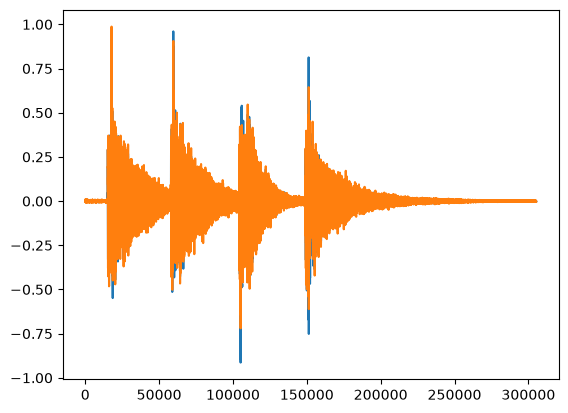

In [11]:
# YOUR CODE HERE
Audio(y.T, rate = sr/2)
plt.plot(y)
plt.show()


**Answer:** YOUR ANSWER HERE
# The speed has been changed.

### Stereo to Mono

Write a function called `to_mono` which
1. Converts any audio data (one or more channels) into a single channel (mono)
2. Normalizes the new audio to be between -1 and 1

**You may only use base Python and NumPy to write your function**.

In [ ]:
# YOUR CODE HERE
import numpy as np
def to_mono(samples):
    if samples.ndim == 1:
        return samples
    y_mono = samples.mean(axis=1)
    y_mono = y_mono/np.max(np.abs(y_mono))
    return y_mono



Use your function to convert the `drums.wav` audio to mono (save this audio as a new variable) and write this monophonic audio to a new file called `drums_mono.wav` with the same sample rate.

In [ ]:
# YOUR CODE HERE
y_mono = to_mono(y)
y, y_mono


(array([[ 0.00271606,  0.00494385],
        [ 0.00234985,  0.00518799],
        [ 0.00183105,  0.00506592],
        ...,
        [-0.00054932, -0.00106812],
        [-0.00097656, -0.00152588],
        [-0.00134277, -0.00186157]], shape=(305291, 2)),
 array([ 0.0040285 ,  0.00396431,  0.00362726, ..., -0.00085064,
        -0.00131609, -0.00168523], shape=(305291,)))

### Waveform

Plot the resulting monophonic waveform with time (in seconds) on the x-axis and amplitude on the y-axis. Make sure to give the plot a title and to label the axes. You must use `matplotlib` to create your plot; you may not use `librosa`.

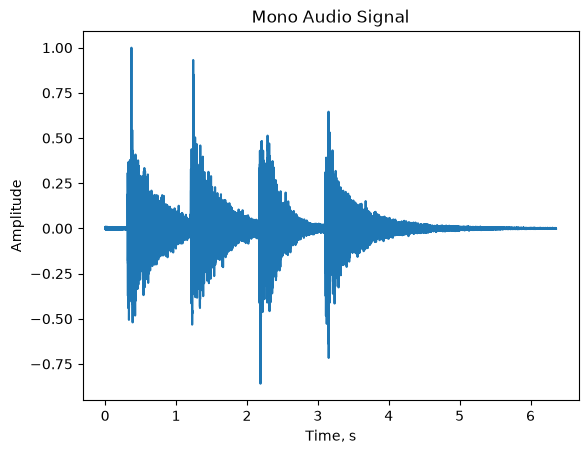

In [23]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
# plt.plot(y_mono)
samples = len(y) / sr
x = np.linspace(0, samples, len(y))
plt.xlabel("Time, s")
plt.ylabel("Amplitude")
plt.title("Mono Audio Signal")
plt.plot(x, y_mono)
plt.show()



### Extra Challenge

Plot the original **stereophonic** waveform in a new figure with two vertically-stacked subfigures (one for each channel). Clearly label each subfigure. Make sure that both subfigures use the same x-axis (time in seconds).

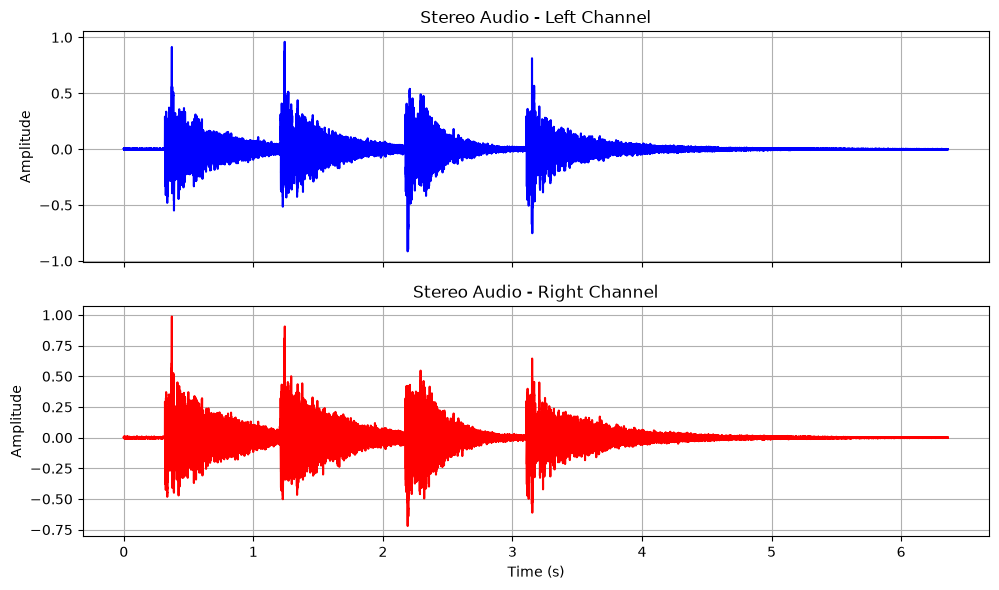

In [55]:
# YOUR CODE HERE

# Calculate time in seconds
time = len(y) / sr
x = np.linspace(0, time, len(y))

# Create 2 vertically-stacked subplots in 1 figure sharing the x-axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top Subfigure: Left Channel
ax1.plot(x, y[:, 0], color='blue')
ax1.set_title("Stereo Audio - Left Channel")
ax1.set_ylabel("Amplitude")
ax1.grid(True)

# Bottom Subfigure: Right Channel
ax2.plot(x, y[:, 1], color='red')
ax2.set_title("Stereo Audio - Right Channel")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Amplitude")
ax2.grid(True)

plt.tight_layout()
plt.show()